# From a spectrum to one number

An IR spectrum is a few hundred absorbance values. A crystallization model needs one value per time that follows the **dissolved solute**. This notebook shows, picture by picture, the two ways the PAT workflow gets that value:

1. **Band height**, for a solute with a band the solvent leaves free. Example: caffeine in water.
2. **Whole-spectrum score**, for a solute hidden under the solvent bands. Example: azithromycin in ethyl acetate.

Each part reads one run from its native iC IR file and ends by checking the result against the reduced table in the repository.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

# Folders that hold the run folders of each dataset (the raw files are not in the repository).
CAFFEINE_RUNS = Path(r"<folder that holds the caffeine run folders>")
AZITHROMYCIN_RUNS = Path(r"<folder that holds the azithromycin run folders>")

# The dataset descriptions and the run clock are in examples/pat of the repository; find its root from this notebook.
ROOT = next(folder for folder in (Path.cwd(), *Path.cwd().parents) if (folder / "examples" / "pat" / "reduce_runs.py").is_file())
sys.path.insert(0, str(ROOT))

from examples.pat import dataset, reduce_runs
from PharmaPy import PATReaders, PATSignals

ZERO_CELSIUS = 273.15  # [K]
# Slurry, dissolved, solvent only and fitted curve; then two neutrals for constructions and derived signals.
BLUE, ORANGE, AQUA, YELLOW, INK, MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#2b2a27", "#8a8882"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "figure.dpi": 110,
                     "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left"})


def window_mean(time, values, window):
    """Return the mean of the rows of ``values`` taken between two times [s] of the run clock."""
    inside = (time >= window[0]) & (time <= window[1])
    return values[inside].mean(axis=0)

## Part 1. Band height: caffeine in water

Read the spectra of one run and put them on the run clock (time zero is the start of the temperature program).

In [2]:
case = ROOT / "examples" / "pat" / "caffeine"
description = dataset.load_description(case)
run = next(item for item in description["runs"] if item["id"] == "high_seed_slow_cool")
folder = CAFFEINE_RUNS / run["folder"]
(ir_file,), (fbrm_file,) = folder.glob("*.iCIR"), folder.glob("*.icFbrm")

ir = PATReaders.read_ic_spectra(ir_file)
first_fbrm_sample = PATReaders.read_ic_fbrm(fbrm_file).time[0].item()  # this dataset places its clock by the FBRM
origin = reduce_runs.run_clock_origin(first_fbrm_sample, run, description)
time, wavenumber, absorbance = reduce_runs.timed_spectra(ir, origin, run["fbrm_local_time_utc_offset_h"])

print("spectra", absorbance.shape, "| run clock from %.0f to %.0f s" % (time[0], time[-1]))

spectra (663, 589) | run clock from -1207 to 41902 s


Three moments of the run have a known state. The windows come from the dataset description; each spectrum below is the mean of the spectra in its window.

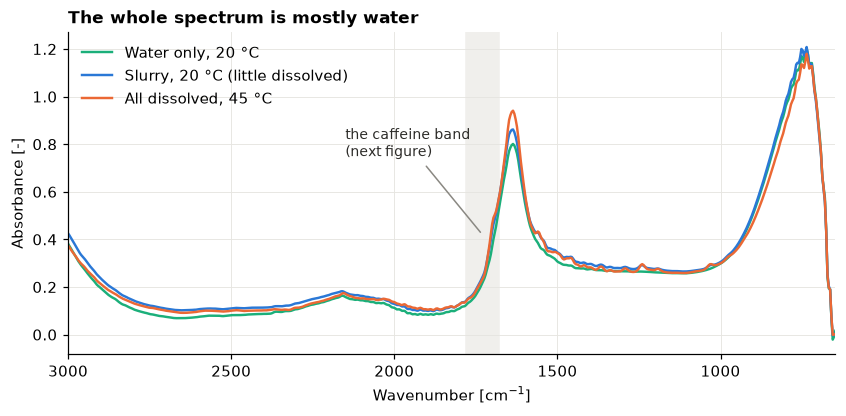

In [3]:
windows = description["band_calibration"]
moments = {  # name: (window on the run clock [s], colour)
    "Water only, 20 \u00b0C": (windows["solvent_window_s"], AQUA),
    "Slurry, 20 \u00b0C (little dissolved)": (windows["slurry_start_window_s"], BLUE),
    "All dissolved, 45 \u00b0C": (windows["dissolved_windows_s"][0], ORANGE),
}
spectra = {name: window_mean(time, absorbance, window) for name, (window, _) in moments.items()}

band = description["ir_band"]
peak, anchors = band["peak_cm-1"], band["baseline_cm-1"]  # [cm-1]

fig, ax = plt.subplots(figsize=(9, 3.8))
for name, (_, colour) in moments.items():
    ax.plot(wavenumber, spectra[name], color=colour, lw=1.6, label=name)
ax.axvspan(1780, 1680, color="#f0efec", zorder=0)
ax.annotate("the caffeine band\n(next figure)", xy=(1730, 0.42), xytext=(2150, 0.75), color=INK, fontsize=9,
            arrowprops={"arrowstyle": "-", "color": MUTED})
ax.set_xlim(wavenumber.max(), wavenumber.min())
ax.set(xlabel="Wavenumber [cm$^{-1}$]", ylabel="Absorbance [-]", title="The whole spectrum is mostly water")
ax.legend(frameon=False);

Zoom in. Near 1700 cm$^{-1}$ caffeine has a band that water leaves free. The recipe:

1. Read the absorbance at the **peak** (1700 cm$^{-1}$).
2. Draw a straight **baseline** through two **anchor** points with no caffeine band (1760 and 1720 cm$^{-1}$) and extend it to the peak.
3. The signal is the peak minus the baseline: the **band height**.

Both anchors are on the left because the strong water band at 1640 cm$^{-1}$ fills the right side.

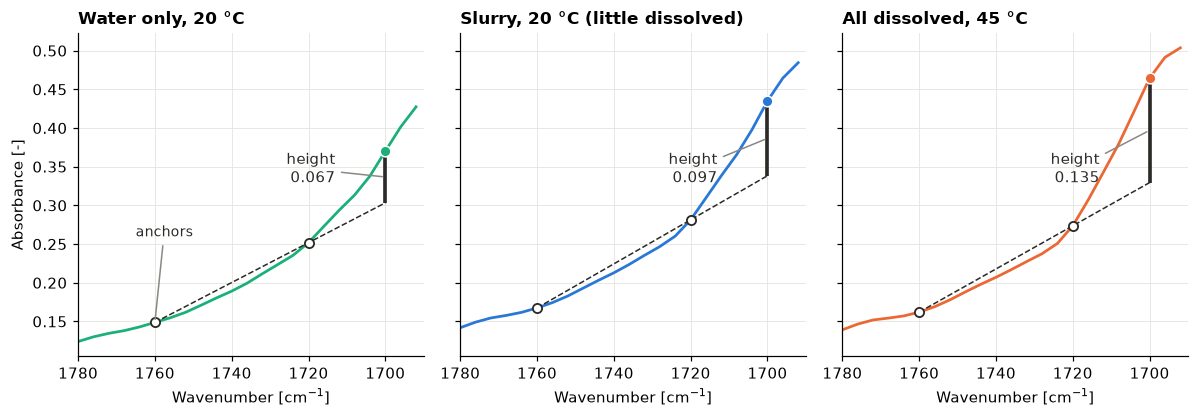

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.9), sharey=True)
zoom = (wavenumber <= 1780) & (wavenumber >= 1690)
for ax, (name, (_, colour)) in zip(axes, moments.items()):
    spectrum = spectra[name]
    at = {position: float(spectrum[np.argmin(np.abs(wavenumber - position))]) for position in (*anchors, peak)}  # [-]
    slope = (at[anchors[1]] - at[anchors[0]]) / (anchors[1] - anchors[0])  # [1/cm-1]
    baseline_at_peak = at[anchors[1]] + slope * (peak - anchors[1])  # [-]
    height = at[peak] - baseline_at_peak  # [-]
    ax.plot(wavenumber[zoom], spectrum[zoom], color=colour, lw=1.8)
    ax.plot([anchors[0], peak], [at[anchors[0]], baseline_at_peak], color=INK, lw=1.0, ls="--")
    ax.plot(anchors, [at[anchors[0]], at[anchors[1]]], "o", color="white", mec=INK, mew=1.2, ms=6)
    ax.plot([peak, peak], [baseline_at_peak, at[peak]], color=INK, lw=2.4, solid_capstyle="butt")
    ax.plot([peak], [at[peak]], "o", color=colour, mec="white", ms=7)
    ax.annotate("height\n%.3f" % height, xy=(peak, (at[peak] + baseline_at_peak) / 2), xytext=(1713, 0.33),
                color=INK, fontsize=10, ha="right", arrowprops={"arrowstyle": "-", "color": MUTED})
    ax.set_xlim(1780, 1690)
    ax.set(xlabel="Wavenumber [cm$^{-1}$]", title=name)
axes[0].set_ylabel("Absorbance [-]")
axes[0].annotate("anchors", xy=(anchors[0], spectra[next(iter(moments))][np.argmin(np.abs(wavenumber - anchors[0]))]),
                 xytext=(1765, 0.26), color=INK, fontsize=9, arrowprops={"arrowstyle": "-", "color": MUTED})
fig.tight_layout()

The same arithmetic in numbers, for the water-only spectrum. The baseline at 1700 is the anchor at 1720 plus half of the step from 1760 to 1720, because 1700 lies half a step further on.

In [5]:
spectrum = spectra[next(iter(moments))]
a1760, a1720, a1700 = (float(spectrum[np.argmin(np.abs(wavenumber - position))]) for position in (1760.0, 1720.0, 1700.0))  # [-]
baseline_at_peak = a1720 + 0.5 * (a1720 - a1760)  # [-]
print("absorbance at 1760, 1720, 1700 cm-1 : %.4f  %.4f  %.4f" % (a1760, a1720, a1700))
print("baseline at 1700 cm-1               : %.4f" % baseline_at_peak)
print("band height                         : %.4f" % (a1700 - baseline_at_peak))
print("PATSignals.band_height gives         : %.4f" % PATSignals.band_height(wavenumber, spectrum, peak, tuple(anchors)))

absorbance at 1760, 1720, 1700 cm-1 : 0.1488  0.2518  0.3701
baseline at 1700 cm-1               : 0.3033
band height                         : 0.0668
PATSignals.band_height gives         : 0.0668


**Why subtract a baseline?** The whole spectrum moves up and down with the contact between probe and liquid. A shift moves the peak and the anchors together, so the height does not see it.

In [6]:
shift = 0.05  # [-] an invented upward shift of the whole spectrum
print("absorbance at the peak : %.4f, shifted %.4f" % (a1700, a1700 + shift))
print("band height            : %.4f, shifted %.4f"
      % (PATSignals.band_height(wavenumber, spectrum, peak, tuple(anchors)), PATSignals.band_height(wavenumber, spectrum + shift, peak, tuple(anchors))))

absorbance at the peak : 0.3701, shifted 0.4201
band height            : 0.0668, shifted 0.0668


Do this for every spectrum and the run becomes one curve. The band height follows the dissolved caffeine: up while the solid dissolves on heating, flat while everything is dissolved, down when it crystallizes on cooling. Right after the caffeine is added, at time zero, the height overshoots and then settles as the hydrate forms. Water alone already reads about 0.067, so zero caffeine is not zero height.

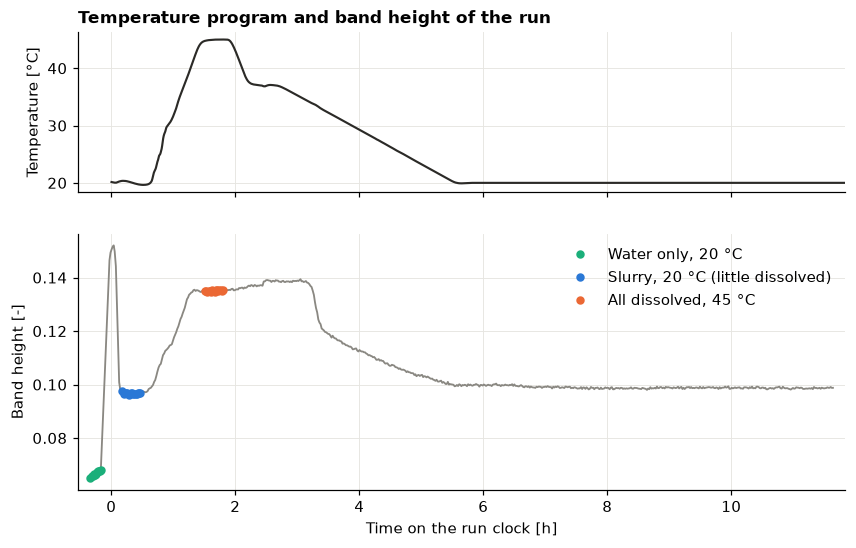

In [7]:
height = PATSignals.band_height(wavenumber, absorbance, peak, tuple(anchors))  # [-] one value per spectrum
log = dataset.read_reduced(case, run["id"], "temperature")

fig, (top, bottom) = plt.subplots(2, 1, figsize=(9, 5.4), sharex=True, height_ratios=(1, 1.6))
top.plot(log["time"] / 3600, log["external_temperature"] - ZERO_CELSIUS, color=INK, lw=1.4)
top.set(ylabel="Temperature [\u00b0C]", title="Temperature program and band height of the run")
bottom.plot(time / 3600, height, color=MUTED, lw=1.2)
for name, (window, colour) in moments.items():
    inside = (time >= window[0]) & (time <= window[1])
    bottom.plot(time[inside] / 3600, height[inside], "o", color=colour, ms=4.5, label=name)
bottom.set(xlabel="Time on the run clock [h]", ylabel="Band height [-]", xlim=(time[0] / 3600 - 0.2, time[-1] / 3600 + 0.2))
bottom.legend(frameon=False, loc="upper right");

In [8]:
reduced = dataset.read_reduced(case, run["id"], "ir")
print("largest difference from the reduced table: %.1e (the table keeps five decimals)" % np.abs(height - reduced["band_height"]).max())

largest difference from the reduced table: 5.0e-06 (the table keeps five decimals)


## Part 2. Whole-spectrum score: azithromycin in ethyl acetate

Ethyl acetate absorbs wherever azithromycin does, so there is no free band to measure. The score uses all points between 900 and 1800 cm$^{-1}$ at once.

Read the reference run and give every spectrum the liquid temperature at its sample time.

In [9]:
case = ROOT / "examples" / "pat" / "azithromycin"
description = dataset.load_description(case)
settings = description["ir_score"]
run = next(item for item in description["runs"] if item["id"] == settings["reference_run"])
(ir_file,) = (AZITHROMYCIN_RUNS / run["folder"]).glob("*.iCIR")

ir = PATReaders.read_ic_spectra(ir_file)
origin = reduce_runs.run_clock_origin(None, run, description)
log = dataset.read_reduced(case, run["id"], "temperature")
time, temperature, wavenumber, absorbance = reduce_runs.spectra_with_temperature(
    *reduce_runs.timed_spectra(ir, origin, run["fbrm_local_time_utc_offset_h"]), log["time"], log[settings["temperature_column"]])

reference_temperature = settings["reference_temperature_K"]  # [K] the seeding hold, 37 C
print("spectra", absorbance.shape, "| temperatures from %.1f to %.1f C" % (temperature.min() - ZERO_CELSIUS, temperature.max() - ZERO_CELSIUS))

spectra (823, 589) | temperatures from 19.9 to 44.9 C


Two moments of this run have a known state: **all dissolved** (the hold at 37 °C before seeding) and **slurry** (the hold at 20 °C at the start, with much of the solute as solid). Their spectra look almost the same. Points where the solution absorbs more than 1.3 are left out: they sit on ethyl acetate bands too strong to respond linearly.

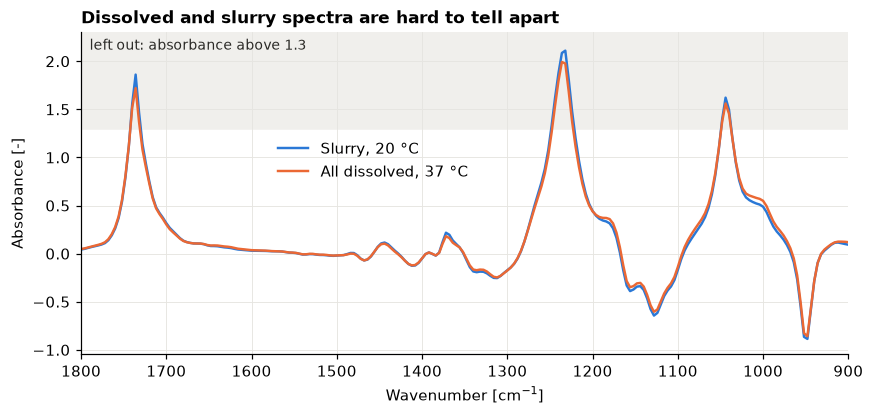

In [10]:
lower, upper = settings["wavenumber_window_cm-1"]  # [cm-1]
inside = (wavenumber >= lower) & (wavenumber <= upper)
raw_dissolved = window_mean(time, absorbance, settings["dissolved_window_s"])
raw_slurry = window_mean(time, absorbance, settings["slurry_window_s"])

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(wavenumber[inside], raw_slurry[inside], color=BLUE, lw=1.6, label="Slurry, 20 \u00b0C")
ax.plot(wavenumber[inside], raw_dissolved[inside], color=ORANGE, lw=1.6, label="All dissolved, 37 \u00b0C")
ax.axhspan(settings["maximum_absorbance"], 2.3, color="#f0efec", zorder=0)
ax.text(1790, 2.12, "left out: absorbance above %.1f" % settings["maximum_absorbance"], color=INK, fontsize=9)
ax.set_xlim(upper, lower)
ax.set_ylim(top=2.3)
ax.set(xlabel="Wavenumber [cm$^{-1}$]", ylabel="Absorbance [-]", title="Dissolved and slurry spectra are hard to tell apart")
ax.legend(frameon=False, loc="center", bbox_to_anchor=(0.38, 0.6));

### Step 1. Take the temperature out

A spectrum changes with temperature even when nothing dissolves or crystallizes. In this run the solution stayed clear while it cooled from 36 to 21 °C, so that stretch shows the temperature effect alone. A straight line per spectral point captures it, and every spectrum is then moved to 37 °C.

The figure shows one spectral point: as measured on the left, moved to 37 °C on the right.

usable spectral points: 214 | clear-solution spectra: 152


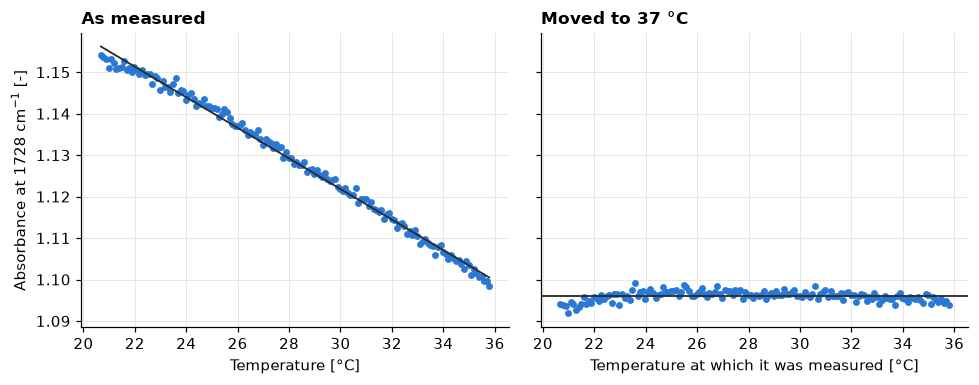

In [11]:
clear = (time >= settings["clear_solution_window_s"][0]) & (time <= settings["clear_solution_window_s"][1])
level, per_kelvin, _ = PATSignals.temperature_effect(absorbance[clear], temperature[clear], reference_temperature)
keep = PATSignals.usable_points(wavenumber, level, lower, upper, settings["maximum_absorbance"])
at_reference = PATSignals.at_reference_temperature(absorbance, temperature, per_kelvin, reference_temperature)
moved = at_reference[:, keep]  # [-] spectra at 37 C, usable points only
axis = wavenumber[keep]  # [cm-1]
print("usable spectral points:", int(keep.sum()), "| clear-solution spectra:", int(clear.sum()))

point = int(np.flatnonzero(keep)[np.argmax(np.abs(per_kelvin[keep]))])  # the usable point that changes most with temperature
celsius = temperature[clear] - ZERO_CELSIUS  # [C]
fig, (left, right) = plt.subplots(1, 2, figsize=(9, 3.6), sharey=True)
left.plot(celsius, absorbance[clear, point], "o", color=BLUE, ms=3.5)
line = level[point] + per_kelvin[point] * (np.array([celsius.min(), celsius.max()]) + ZERO_CELSIUS - reference_temperature)
left.plot([celsius.min(), celsius.max()], line, color=INK, lw=1.2)
left.set(xlabel="Temperature [\u00b0C]", ylabel="Absorbance at %.0f cm$^{-1}$ [-]" % wavenumber[point], title="As measured")
right.plot(celsius, at_reference[clear, point], "o", color=BLUE, ms=3.5)
right.axhline(level[point], color=INK, lw=1.2)
right.set(xlabel="Temperature at which it was measured [\u00b0C]", title="Moved to 37 \u00b0C")
fig.tight_layout()

### Step 2. Find the fingerprint of the solute

Subtract the slurry spectrum from the dissolved spectrum, both at 37 °C. What is left is the change of the spectrum when that amount of solute goes into solution: the **fingerprint** of dissolved azithromycin. It is small, a few hundredths of an absorbance unit, but it has a clear shape.

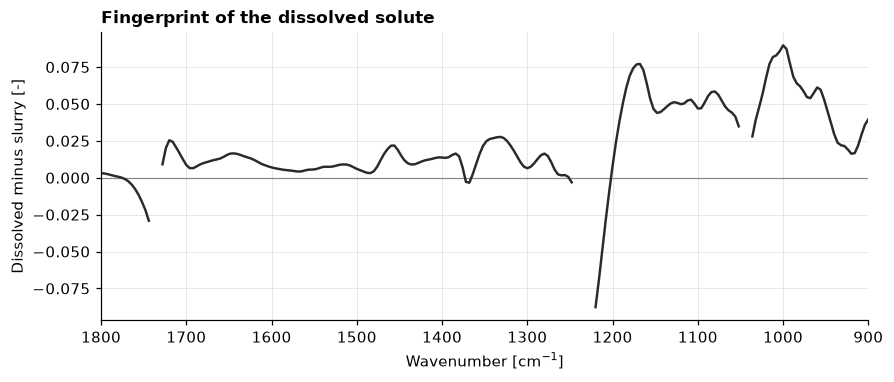

In [12]:
dissolved = window_mean(time, moved, settings["dissolved_window_s"])  # [-] this run with all its solute dissolved
slurry = window_mean(time, moved, settings["slurry_window_s"])  # [-]
fingerprint = dissolved - slurry  # [-]


def with_gaps(values):
    """Return values on the whole axis, with NaN at the points left out, so a line breaks there."""
    full = np.full(wavenumber.shape, np.nan)
    full[keep] = values
    return full[inside]


fig, ax = plt.subplots(figsize=(9, 3.4))
ax.axhline(0.0, color=MUTED, lw=0.8)
ax.plot(wavenumber[inside], with_gaps(fingerprint), color=INK, lw=1.6)
ax.set_xlim(upper, lower)
ax.set(xlabel="Wavenumber [cm$^{-1}$]", ylabel="Dissolved minus slurry [-]", title="Fingerprint of the dissolved solute");

### Step 3. Ask every spectrum how much fingerprint it holds

For each spectrum, take its difference from the dissolved spectrum and find how many fingerprints reproduce it. That number is the **score**:

- score 0: the spectrum equals the dissolved one, so everything is in solution;
- score −1: one whole fingerprint is missing, so as much solute has left the solution as in the slurry.

Three more terms are fitted at the same time for the contact between probe and liquid: a **scale** of the whole spectrum, an **offset** and a **tilt** of its baseline. They keep such changes out of the score.

The figure shows three spectra taken while the solute crystallizes. Dots: measured difference from the dissolved spectrum. Line: what the score and the three contact terms reproduce.

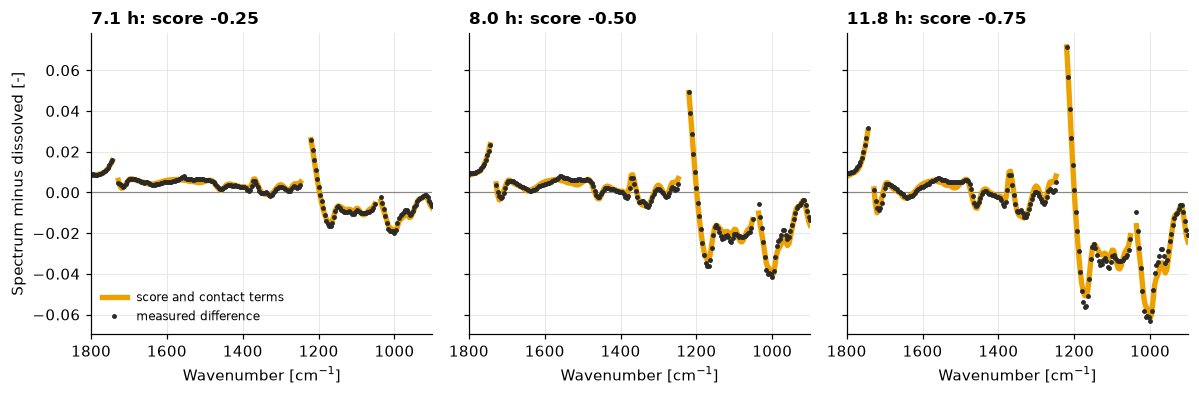

In [13]:
terms = PATSignals.score_terms(axis, moved, dissolved, fingerprint)
position = (axis - axis.mean()) / np.ptp(axis)  # [-] shape of the tilt term
after_seeding = time > run["seeding_time_s"]
examples = [int(np.flatnonzero(after_seeding)[np.argmin(np.abs(terms.score[after_seeding] - target))]) for target in (-0.25, -0.5, -0.75)]

fig, axes = plt.subplots(1, 3, figsize=(11, 3.7), sharey=True)
for ax, row in zip(axes, examples):
    fitted = terms.score[row] * fingerprint + terms.scale[row] * dissolved + terms.offset[row] + terms.tilt[row] * position
    ax.axhline(0.0, color=MUTED, lw=0.8)
    ax.plot(wavenumber[inside], with_gaps(fitted), color=YELLOW, lw=3.5, label="score and contact terms")
    ax.plot(axis, moved[row] - dissolved, "o", color=INK, ms=2.2, label="measured difference")
    ax.set_xlim(upper, lower)
    ax.set(xlabel="Wavenumber [cm$^{-1}$]", title="%.1f h: score %.2f" % (time[row] / 3600, terms.score[row]))
axes[0].set_ylabel("Spectrum minus dissolved [-]")
axes[0].legend(frameon=False, fontsize=8, loc="lower left")
fig.tight_layout()

The difference keeps the shape of the fingerprint, upside down, and grows as the solute crystallizes. The score is the size of that shape.

Over the whole run the score reads like this. It starts near −1 (slurry) and rises to 0 as the solid dissolves on heating. It stays near 0 through the hold at 37 °C and the whole cooling ramp: in this run the solution stayed clear until it reached 20 °C. The small step at 2.6 h is at the seed addition. Then the score falls as the solute crystallizes. The three circles are the spectra of the figure above.

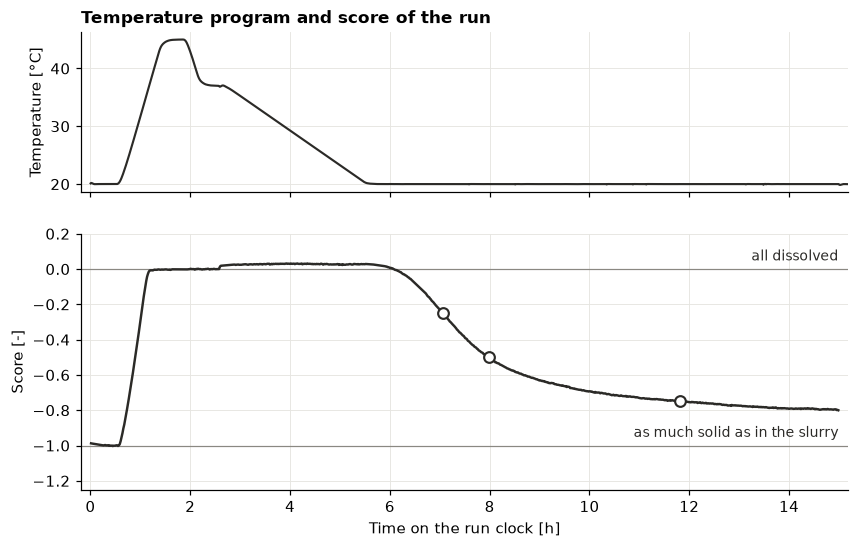

In [14]:
fig, (top, bottom) = plt.subplots(2, 1, figsize=(9, 5.4), sharex=True, height_ratios=(1, 1.6))
top.plot(log["time"] / 3600, log[settings["temperature_column"]] - ZERO_CELSIUS, color=INK, lw=1.4)
top.set(ylabel="Temperature [\u00b0C]", title="Temperature program and score of the run")
bottom.axhline(0.0, color=MUTED, lw=0.8)
bottom.axhline(-1.0, color=MUTED, lw=0.8)
bottom.plot(time / 3600, terms.score, color=INK, lw=1.6)
bottom.plot(time[examples] / 3600, terms.score[examples], "o", color="white", mec=INK, mew=1.4, ms=7)
bottom.text(time[-1] / 3600, 0.03, "all dissolved", color=INK, fontsize=9, ha="right", va="bottom")
bottom.text(time[-1] / 3600, -0.97, "as much solid as in the slurry", color=INK, fontsize=9, ha="right", va="bottom")
bottom.set(xlabel="Time on the run clock [h]", ylabel="Score [-]", ylim=(-1.25, 0.2), xlim=(time[0] / 3600 - 0.2, time[-1] / 3600 + 0.2));

In [15]:
reduced = dataset.read_reduced(case, run["id"], "ir")
print("largest difference from the reduced table: %.1e (rounding: the tables keep five decimals and 0.001 K)" % np.abs(terms.score - reduced["score"]).max())
print("contact terms over the run: scale %.3f to %.3f, offset %.3f to %.3f, tilt %.3f to %.3f"
      % (terms.scale.min(), terms.scale.max(), terms.offset.min(), terms.offset.max(), terms.tilt.min(), terms.tilt.max()))

largest difference from the reduced table: 1.1e-05 (rounding: the tables keep five decimals and 0.001 K)
contact terms over the run: scale -0.002 to 0.002, offset -0.001 to 0.008, tilt -0.001 to 0.009


## What the number is, and is not

- Both numbers follow the dissolved solute, and neither is a concentration yet. The calibration step turns the band height or the score into kg of solute per kg of solvent, using moments of known composition.
- The band height needs a free band. Peak and anchors belong to the compound and solvent and are set in the dataset description (`ir_band`).
- The score needs no free band, but it needs two spectra of known state in one run and a clear-solution stretch for the temperature effect. They are set in the description too (`ir_score`).
- The score is counted from each run's own dissolved spectrum, so it measures the change of the dissolved solute within a run.